# Nguyễn Thành Trí - MSSV: 6451071079
## Bài 5: Ứng dụng nhận dạng chữ số viết tay MNIST (Mục 7 trang 27 - 31)

In [1]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets, tree, metrics
from sklearn.model_selection import train_test_split
from PIL import Image, ImageOps

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("Dataset", os.path.basename(rel_path)),
        os.path.join("..", "Dataset", os.path.basename(rel_path)),
        os.path.join("..", "..", "Dataset", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file: {rel_path}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


### Bước 1 & 2: Tải dữ liệu MNIST và biểu diễn 4 mẫu dữ liệu huấn luyện
- Tải tập dữ liệu chữ số viết tay Digits từ scikit-learn (`datasets.load_digits()`).
- Hiển thị 4 mẫu hình ảnh đầu tiên tương ứng với các chữ số 0, 1, 2, 3.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Tổng số lượng mẫu ảnh chữ số: 1797
Kích thước mỗi ảnh: (8, 8)


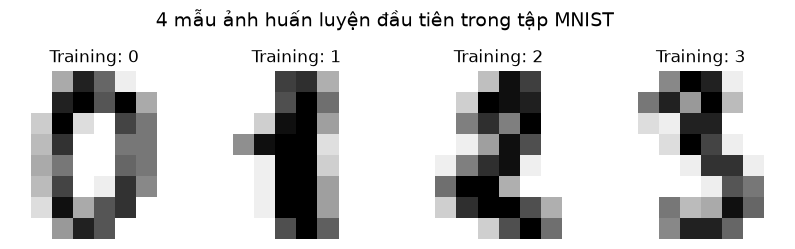

In [2]:
# Bước 1 & 2: Tải dữ liệu và biểu diễn 4 mẫu đầu tiên
digits = datasets.load_digits()

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Tổng số lượng mẫu ảnh chữ số: {len(digits.images)}")
print(f"Kích thước mỗi ảnh: {digits.images[0].shape}")

# Biểu diễn 4 mẫu dữ liệu huấn luyện tương ứng với 4 lớp 0, 1, 2, 3
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
images_and_labels = list(zip(digits.images, digits.target))
for ax, (image, label) in zip(axes, images_and_labels[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title(f'Training: {label}')
plt.suptitle("4 mẫu ảnh huấn luyện đầu tiên trong tập MNIST", fontsize=14)
plt.show()

### Bước 3 & 4: Chuyển đổi ma trận ảnh 8x8 thành vector 1x64 và xây dựng cây ID3
- Duỗi ma trận 8x8 thành vector đặc trưng 64 chiều (`digits.images.reshape((n_samples, -1))`).
- Chia tập dữ liệu 80% huấn luyện và 20% kiểm thử (`test_size=0.2, shuffle=False`).
- Huấn luyện mô hình cây quyết định ID3 với tiêu chí entropy (`DecisionTreeClassifier(criterion="entropy", random_state=33)`).

In [3]:
# Bước 3 & 4: Chuyển đổi dữ liệu và huấn luyện cây ID3
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))

# Chia dữ liệu: 80% huấn luyện, 20% kiểm thử
X_train, X_test, y_train, y_test = train_test_split(
    data, digits.target, test_size=0.2, shuffle=False
)

# Xây dựng và huấn luyện mô hình cây quyết định ID3
classifier = tree.DecisionTreeClassifier(criterion="entropy", random_state=33)
classifier.fit(X_train, y_train)

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Kích thước dữ liệu sau khi duỗi: {data.shape}")
print(f"Kích thước tập huấn luyện X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Kích thước tập kiểm thử X_test: {X_test.shape}, y_test: {y_test.shape}")
print("Huấn luyện mô hình cây quyết định ID3 thành công.")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước dữ liệu sau khi duỗi: (1797, 64)
Kích thước tập huấn luyện X_train: (1437, 64), y_train: (1437,)
Kích thước tập kiểm thử X_test: (360, 64), y_test: (360,)
Huấn luyện mô hình cây quyết định ID3 thành công.


### Bước 5: Dự đoán trên tập kiểm thử và đánh giá hiệu năng
- Dự đoán nhãn chữ số trên tập kiểm thử X_test.
- Trực quan hóa một số mẫu dự đoán cùng hình ảnh tương ứng.
- Đánh giá thông số đạt được qua Accuracy, Classification Report và Confusion Matrix.

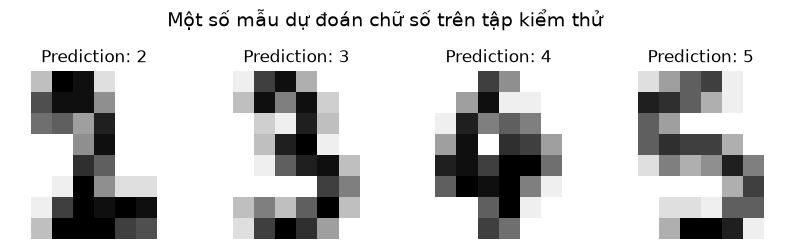

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Accuracy: 0.7972

Báo cáo phân lớp (Classification Report):
              precision    recall  f1-score   support

           0       0.86      0.89      0.87        35
           1       0.72      0.64      0.68        36
           2       0.76      0.74      0.75        35
           3       0.69      0.59      0.64        37
           4       0.86      0.84      0.85        37
           5       0.80      0.95      0.86        37
           6       0.97      0.95      0.96        37
           7       0.78      0.86      0.82        36
           8       0.79      0.82      0.81        33
           9       0.72      0.70      0.71        37

    accuracy                           0.80       360
   macro avg       0.80      0.80      0.79       360
weighted avg       0.80      0.80      0.79       360



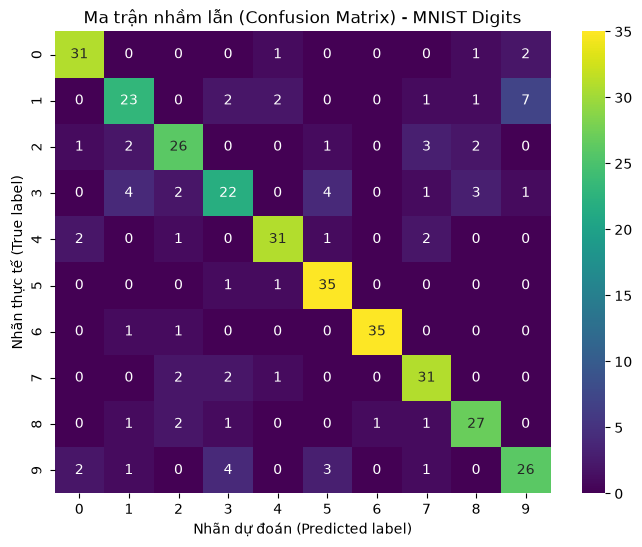

In [4]:
# Bước 5: Dự đoán trên tập kiểm thử và đánh giá
predicted = classifier.predict(X_test)

# Biểu diễn một vài kết quả dự đoán (4 mẫu đầu tiên của tập kiểm thử)
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
images_and_predictions = list(zip(digits.images[len(X_train):], predicted))
for ax, (image, prediction) in zip(axes, images_and_predictions[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title(f'Prediction: {prediction}')
plt.suptitle("Một số mẫu dự đoán chữ số trên tập kiểm thử", fontsize=14)
plt.show()

# Đánh giá các thông số đạt được
acc_id3 = metrics.accuracy_score(y_test, predicted)
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Accuracy: {acc_id3:.4f}")
print()
print("Báo cáo phân lớp (Classification Report):")
print(metrics.classification_report(y_test, predicted))

# Ma trận nhầm lẫn (Confusion Matrix)
plt.figure(figsize=(8, 6))
cm_digits = metrics.confusion_matrix(y_test, predicted)
sns.heatmap(cm_digits, annot=True, fmt="d", cmap="viridis",
            xticklabels=range(10), yticklabels=range(10))
plt.title("Ma trận nhầm lẫn (Confusion Matrix) - MNIST Digits")
plt.xlabel("Nhãn dự đoán (Predicted label)")
plt.ylabel("Nhãn thực tế (True label)")
plt.show()

### Bước 6: Nhận dạng chữ số viết tay từ ảnh chụp thực tế bên ngoài
- Sử dụng thư viện Pillow để mở và tiền xử lý ảnh số viết tay bên ngoài (`test_image_Bai7.jpg` và `test_image_Bai7(1).jpg`).
- Chuyển đổi sang ảnh xám (`convert("L")`), nghịch đảo màu (`ImageOps.invert`) và thu phóng về ma trận 8x8.
- Làm rõ nét ảnh bằng kỹ thuật phân ngưỡng nhị phân (thresholding).
- Đưa ma trận 1x64 vào mô hình cây quyết định ID3 để dự đoán nhãn chữ số.

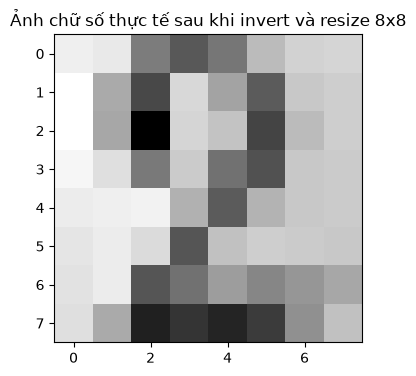

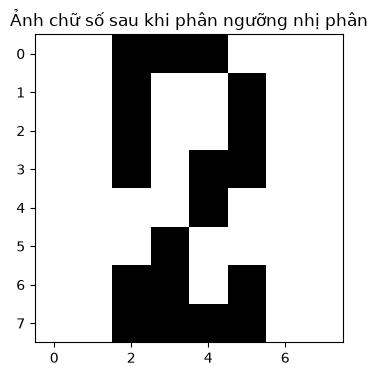

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Nhãn dự đoán cho ảnh test_image_Bai7.jpg: [2]
Nhãn dự đoán cho ảnh test_image_Bai7(1).jpg: [1]


In [5]:
# Bước 6: Nhận dạng ảnh chụp thực tế bên ngoài
# 1. Đọc và tiền xử lý ảnh test_image_Bai7.jpg
img_path1 = get_data_path("test_image_Bai7.jpg")
img1 = Image.open(img_path1).convert("L").resize((8, 8))
img1 = ImageOps.invert(img1)
im2arr1 = np.array(img1)

plt.figure(figsize=(4, 4))
plt.imshow(im2arr1, cmap=plt.cm.gray_r, interpolation='nearest')
plt.title("Ảnh chữ số thực tế sau khi invert và resize 8x8")
plt.show()

# Duỗi ma trận và phân ngưỡng làm rõ nét ảnh
img1d_1 = im2arr1.reshape([1, 64]).copy()
img1d_1[img1d_1 > 109] = 155
img1d_1[img1d_1 < 110] = 0

plt.figure(figsize=(4, 4))
plt.imshow(img1d_1.reshape((8, 8)), cmap=plt.cm.gray_r, interpolation='nearest')
plt.title("Ảnh chữ số sau khi phân ngưỡng nhị phân")
plt.show()

# Dự đoán bằng mô hình cây ID3
y_pred1 = classifier.predict(img1d_1)
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Nhãn dự đoán cho ảnh test_image_Bai7.jpg: {y_pred1}")

# 2. Thử nghiệm thêm với ảnh test_image_Bai7(1).jpg
img_path2 = get_data_path("test_image_Bai7(1).jpg")
img2 = Image.open(img_path2).convert("L").resize((8, 8))
img2 = ImageOps.invert(img2)
im2arr2 = np.array(img2)

img1d_2 = im2arr2.reshape([1, 64]).copy()
img1d_2[img1d_2 > 109] = 155
img1d_2[img1d_2 < 110] = 0

y_pred2 = classifier.predict(img1d_2)
print(f"Nhãn dự đoán cho ảnh test_image_Bai7(1).jpg: {y_pred2}")